# MIT ELDS Data - EDA

Notebook explores 2020 Presidential Election data from [MIT ELDS](https://electionlab.mit.edu/data#tools).

Raw data and information must be accessed via their website. 

NOTE: There are some discrepencies between this data and official final counts which are described by ELDS in thier data repos. The goal of this notebook is not to verify or replicate the exact final figures, but to demonstrate how this type of data can be worked with and visualized. Therefore results are realistic and aligned but not exact.

In [1]:
import polars as pl

In [2]:
df = pl.read_csv(
    "../data/pres_dataverse_files/PRESIDENT_precinct_general.csv",
    ignore_errors=True
)

In [3]:
print("Shape (rows, columns):", df.shape)  # Returns (row_count, col_count)
print("\nSchema / Data Types:")
print(df.schema)  # Shows column names and data types

Shape (rows, columns): (1982581, 25)

Schema / Data Types:
Schema({'precinct': String, 'office': String, 'party_detailed': String, 'party_simplified': String, 'mode': String, 'votes': Int64, 'county_name': String, 'county_fips': Int64, 'jurisdiction_name': String, 'jurisdiction_fips': Int64, 'candidate': String, 'district': String, 'dataverse': String, 'year': Int64, 'stage': String, 'state': String, 'special': Boolean, 'writein': Boolean, 'state_po': String, 'state_fips': Int64, 'state_cen': Int64, 'state_ic': Int64, 'date': String, 'readme_check': Boolean, 'magnitude': Int64})


In [4]:
print("\nFirst 5 rows:")
print(df.head())  # Displays top rows


First 5 rows:
shape: (5, 25)
┌───────────┬───────────┬───────────┬───────────┬───┬──────────┬───────────┬───────────┬───────────┐
│ precinct  ┆ office    ┆ party_det ┆ party_sim ┆ … ┆ state_ic ┆ date      ┆ readme_ch ┆ magnitude │
│ ---       ┆ ---       ┆ ailed     ┆ plified   ┆   ┆ ---      ┆ ---       ┆ eck       ┆ ---       │
│ str       ┆ str       ┆ ---       ┆ ---       ┆   ┆ i64      ┆ str       ┆ ---       ┆ i64       │
│           ┆           ┆ str       ┆ str       ┆   ┆          ┆           ┆ bool      ┆           │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪══════════╪═══════════╪═══════════╪═══════════╡
│ 060012001 ┆ US        ┆ ALLIANCE  ┆ OTHER     ┆ … ┆ 71       ┆ 2020-11-0 ┆ true      ┆ 1         │
│ 00_002013 ┆ PRESIDENT ┆           ┆           ┆   ┆          ┆ 3         ┆           ┆           │
│ 009015    ┆           ┆           ┆           ┆   ┆          ┆           ┆           ┆           │
│ 060012001 ┆ US        ┆ DEMOCRAT  ┆ DEMOCRAT  ┆ … ┆ 71     

In [5]:
# Allow scroll window to see full df
with pl.Config(tbl_rows=-1, tbl_width_chars=1000):
    display(df.head(10))

precinct,office,party_detailed,party_simplified,mode,votes,county_name,county_fips,jurisdiction_name,jurisdiction_fips,candidate,district,dataverse,year,stage,state,special,writein,state_po,state_fips,state_cen,state_ic,date,readme_check,magnitude
str,str,str,str,str,i64,str,i64,str,i64,str,str,str,i64,str,str,bool,bool,str,i64,i64,i64,str,bool,i64
"""06001200100_002013009015""","""US PRESIDENT""","""ALLIANCE""","""OTHER""","""ABSENTEE""",5,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""ROQUE DE LA FUENTE GUERRA""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""DEMOCRAT""","""DEMOCRAT""","""ABSENTEE""",2841,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""JOSEPH R BIDEN""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""GREEN""","""OTHER""","""ABSENTEE""",15,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""HOWIE HAWKINS""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""LIBERTARIAN""","""LIBERTARIAN""","""ABSENTEE""",11,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""JO JORGENSEN""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""SOCIALISM AND LIBERATION""","""OTHER""","""ABSENTEE""",6,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""GLORIA LA RIVA""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""REPUBLICAN""","""REPUBLICAN""","""ABSENTEE""",108,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""DONALD J TRUMP""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""ALLIANCE""","""OTHER""","""NOT ABSENTEE""",2,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""ROQUE DE LA FUENTE GUERRA""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""DEMOCRAT""","""DEMOCRAT""","""NOT ABSENTEE""",86,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""JOSEPH R BIDEN""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1
"""06001200100_002013009015""","""US PRESIDENT""","""GREEN""","""OTHER""","""NOT ABSENTEE""",1,"""ALAMEDA""",6001,"""ALAMEDA""",6001,"""HOWIE HAWKINS""","""STATEWIDE""","""PRESIDENT""",2020,"""GEN""","""CALIFORNIA""",false,false,"""CA""",6,93,71,"""2020-11-03""",true,1


In [6]:
print("\nSummary Statistics:")
print(df.describe())  # Computes mean, std, min, max, quantiles, etc.


Summary Statistics:
shape: (9, 26)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ statistic ┆ precinct  ┆ office    ┆ party_det ┆ … ┆ state_ic  ┆ date      ┆ readme_ch ┆ magnitud │
│ ---       ┆ ---       ┆ ---       ┆ ailed     ┆   ┆ ---       ┆ ---       ┆ eck       ┆ e        │
│ str       ┆ str       ┆ str       ┆ ---       ┆   ┆ f64       ┆ str       ┆ ---       ┆ ---      │
│           ┆           ┆           ┆ str       ┆   ┆           ┆           ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ count     ┆ 1982581   ┆ 1982581   ┆ 1982581   ┆ … ┆ 1.982581e ┆ 1982581   ┆ 1.982581e ┆ 1.982581 │
│           ┆           ┆           ┆           ┆   ┆ 6         ┆           ┆ 6         ┆ e6       │
│ null_coun ┆ 0         ┆ 0         ┆ 0         ┆ … ┆ 0.0       ┆ 0         ┆ 0.0       ┆ 0.0      │
│ t         ┆           ┆           ┆           ┆   ┆  

In [7]:
# Only US president data included
df['office'].unique().to_list()

['US PRESIDENT']

In [8]:
# Only 2020 election included
df['year'].value_counts()

year,count
i64,u32
2020,1982581


In [9]:
# Who was running? 
print(df['candidate'].unique().to_list())

['BILL LEE', 'BARBARA BELLAR', 'MARK CHARLES AND ADRIAN WALLACE', 'ALICE COOPER', 'JOHN WILLINCK', 'DON BLANKENSHIP', 'F GRAHAM', 'TARA RENEE HUNTER', 'DENVER RIGGLEMAN', 'WILLIE NELSON', 'RICKI SUE KING', 'GOVERNOR CUOMO', 'FRANCES WORKMAN', 'JUDD GREGG', 'RICK SANTORUM', 'MELIXER', 'ROBERT BINDERT', 'BRENDA TAYLOR', 'TINA TURNER', 'BUTTIGIEG', 'RICHARD DUNCAN', 'DAVID COOTWARE', 'CHRISTINA NANOPOLOUS', 'JOHN KASLETT', 'MC GRAVEN', 'BRIAN T CARROLL', 'TIMOTHY EUGENE SCOTT', 'MARNI GREEN', 'ALL OTHERS', 'MR WILINK', 'LABRON JAMES', 'BERNIE SANDERS', 'ROBERT MELESKY', 'KULE KULINSKI', 'RYAN EHRENREICH', 'KASEY WELLS', 'JONATHAN GENTINE', 'PETER EDSON', 'ROBERT MCILWANE', 'CHARLIE BAKER', 'BEN SHAPIRO', 'LIAM J GIBBONS', 'DEBORAH ROUSE', 'STEVE FORBES', 'GEORGE TRIEB', 'DAVID LIEBOW', 'BILL BELICIEK', 'DDR PHIL MCGRAW', 'DONALD DIXON', 'DOUG GRANT', 'ALYSSA FILLION', 'EDWARD SNOWDEN', 'KEVIN MCKEE', 'TERRY KEIM', 'JOHN GIERACH', 'KINGSLEY SMITH AND JOHN W SMITH', 'ANDREW YANG', 'JULIE AN

In [10]:
# More than expected, dive in
result = df.group_by("candidate").agg(
    pl.col("votes").sum().alias("total_votes")).sort("total_votes", descending=True)
print(result)

shape: (543, 2)
┌─────────────────────────────────┬─────────────┐
│ candidate                       ┆ total_votes │
│ ---                             ┆ ---         │
│ str                             ┆ i64         │
╞═════════════════════════════════╪═════════════╡
│ JOSEPH R BIDEN                  ┆ 80973171    │
│ DONALD J TRUMP                  ┆ 73661867    │
│ JO JORGENSEN                    ┆ 1774042     │
│ HOWIE HAWKINS                   ┆ 396274      │
│ WRITEIN                         ┆ 211495      │
│ …                               ┆ …           │
│ KATHRYN GIBSON                  ┆ 0           │
│ HOWARD SHAWN                    ┆ 0           │
│ CHRIS FRANKLIN                  ┆ 0           │
│ PRINCESS KHADIJAH M JACOB-FAMB… ┆ 0           │
│ SHEILA "SAMM" TITTLE AND DAVID… ┆ -1797       │
└─────────────────────────────────┴─────────────┘


In [11]:
samm_results = df.filter(pl.col("candidate").str.contains('"SAMM"'))
print(samm_results)

shape: (1_925, 25)
┌───────────┬───────────┬───────────┬───────────┬───┬──────────┬───────────┬───────────┬───────────┐
│ precinct  ┆ office    ┆ party_det ┆ party_sim ┆ … ┆ state_ic ┆ date      ┆ readme_ch ┆ magnitude │
│ ---       ┆ ---       ┆ ailed     ┆ plified   ┆   ┆ ---      ┆ ---       ┆ eck       ┆ ---       │
│ str       ┆ str       ┆ ---       ┆ ---       ┆   ┆ i64      ┆ str       ┆ ---       ┆ i64       │
│           ┆           ┆ str       ┆ str       ┆   ┆          ┆           ┆ bool      ┆           │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪══════════╪═══════════╪═══════════╪═══════════╡
│ 001       ┆ US        ┆ CONSTITUT ┆ OTHER     ┆ … ┆ 66       ┆ 2020-11-0 ┆ true      ┆ 1         │
│           ┆ PRESIDENT ┆ ION       ┆           ┆   ┆          ┆ 3         ┆           ┆           │
│ 002       ┆ US        ┆ CONSTITUT ┆ OTHER     ┆ … ┆ 66       ┆ 2020-11-0 ┆ true      ┆ 1         │
│           ┆ PRESIDENT ┆ ION       ┆           ┆   ┆          ┆ 3      

In [12]:
# samm_results['votes'].value_coiunts()
samm_results.columns

['precinct',
 'office',
 'party_detailed',
 'party_simplified',
 'mode',
 'votes',
 'county_name',
 'county_fips',
 'jurisdiction_name',
 'jurisdiction_fips',
 'candidate',
 'district',
 'dataverse',
 'year',
 'stage',
 'state',
 'special',
 'writein',
 'state_po',
 'state_fips',
 'state_cen',
 'state_ic',
 'date',
 'readme_check',
 'magnitude']

In [13]:
print(samm_results['votes'].value_counts())

shape: (6, 2)
┌───────┬───────┐
│ votes ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ 7     ┆ 4     │
│ 12    ┆ 1     │
│ 8     ┆ 1     │
│ -1    ┆ 1909  │
│ 10    ┆ 1     │
│ 6     ┆ 9     │
└───────┴───────┘


In [14]:
samm_results['state'].value_counts()

state,count
str,u32
"""NEW MEXICO""",1925


# Visualization

In [15]:
import plotly.express as px

In [16]:
total_votes =  df.group_by("state_po").agg(
    pl.col("votes").sum().alias("total_votes")).sort("total_votes", descending=True)

In [17]:
total_votes

state_po,total_votes
str,i64
"""CA""",17497299
"""TX""",11317039
"""FL""",11143925
"""NY""",8657292
"""PA""",6926445
…,…
"""VT""",370968
"""ND""",361819
"""AK""",357569


In [18]:
# 2. Convert to Pandas for Plotly Express compatibility
total_votes_pd = total_votes.to_pandas()


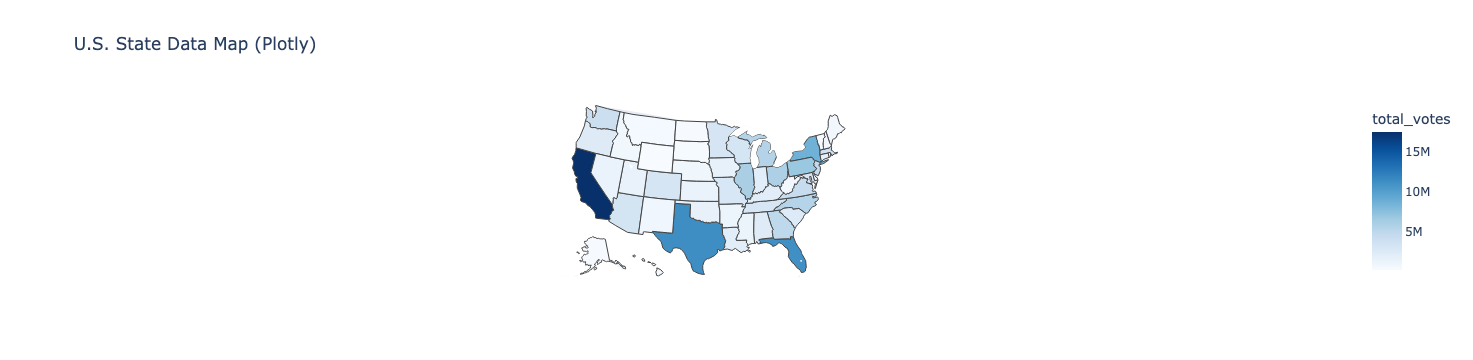

In [21]:

# 3. Create the interactive map
fig = px.choropleth(
    total_votes_pd,
    locations="state_po",  # Column containing 2-letter state codes
    locationmode="USA-states",  # Tells Plotly to look for US state abbreviations
    color="total_votes",  # Column determining the color scale
    color_continuous_scale="Blues",
    scope="usa",  # Zooms the map view specifically to the USA
    title="U.S. State Data Map (Plotly)",
)

# 4. Display the interactive map
fig.show()